In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# RMSD

In [31]:
wt_rmsd= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/001_qc/rmsd.csv')
    wt_rmsd.append(df)

T419R_rmsd= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/001_qc/rmsd.csv')
    T419R_rmsd.append(df)

S466R_rmsd= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/001_qc/rmsd.csv')
    S466R_rmsd.append(df)

In [32]:
# Find global min and max for C-alpha to set consistent Y-axis
all_rmsd = wt_rmsd + T419R_rmsd + S466R_rmsd
y_min = min(df['C-alphas'].min() for df in all_rmsd)
y_max = max(df['C-alphas'].max() for df in all_rmsd)

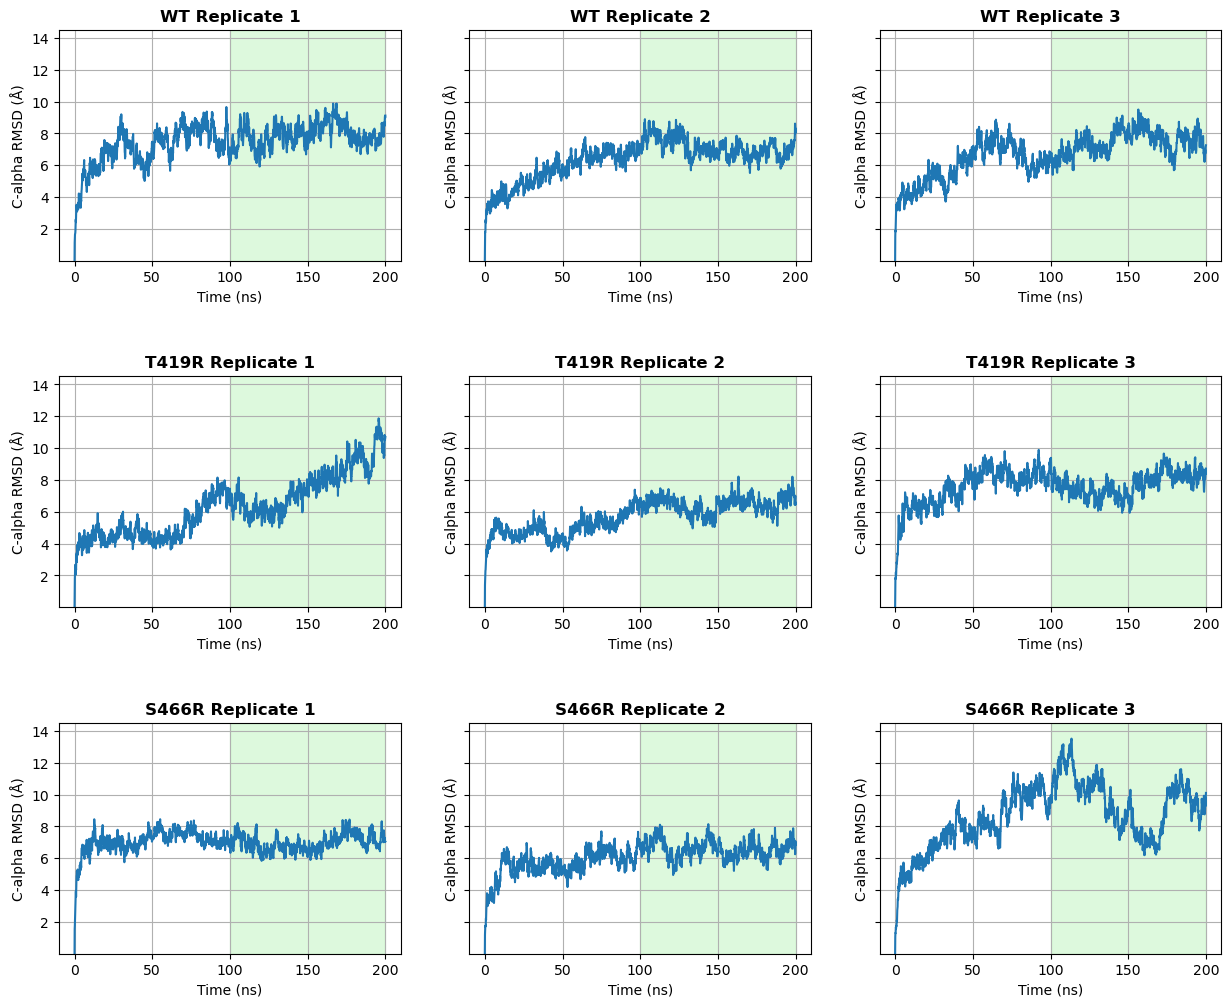

In [33]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharey=True)

# Plot WT replicates
for i, (df, ax) in enumerate(zip(wt_rmsd, axes[0])):
    ax.plot(df['Time (ps)'] / 1000, df['C-alphas'], label='C-alpha')
    ax.axvspan(100, 200, color='lightgreen', alpha=0.3)
    ax.set_title(f'WT Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel('C-alpha RMSD (Å)')
    ax.set_ylim(y_min, y_max+1)
    ax.grid(True)

# Plot T499R replicates
for i, (df, ax) in enumerate(zip(T419R_rmsd, axes[1])):
    ax.plot(df['Time (ps)'] / 1000, df['C-alphas'], label='C-alpha')
    ax.axvspan(100, 200, color='lightgreen', alpha=0.3)
    ax.set_title(f'T419R Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel('C-alpha RMSD (Å)')
    ax.set_ylim(y_min, y_max+1)
    ax.grid(True)

# Plot S466R replicates
for i, (df, ax) in enumerate(zip(S466R_rmsd, axes[2])):
    ax.plot(df['Time (ps)'] / 1000, df['C-alphas'], label='C-alpha')
    ax.axvspan(100, 200, color='lightgreen', alpha=0.3)
    ax.set_title(f'S466R Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel('C-alpha RMSD (Å)')
    ax.set_ylim(y_min, y_max+1)
    ax.grid(True)

plt.subplots_adjust(hspace=0.5)
plt.show()

# Radius of gyration

In [34]:
wt_radius= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/001_qc/radius_axis.csv')
    wt_radius.append(df)

T419R_radius= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/001_qc/radius_axis.csv')
    T419R_radius.append(df)

S466R_radius= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/001_qc/radius_axis.csv')
    S466R_radius.append(df)

In [35]:
# Find global min and max for C-alpha to set consistent Y-axis
all_radius = wt_radius + T419R_radius + S466R_radius
y_min = min(df[col].min() for df in all_radius for col in ['all', 'x-axis', 'y-axis', 'z-axis']) - 2
y_max = max(df['all'].max() for df in all_radius) + 2

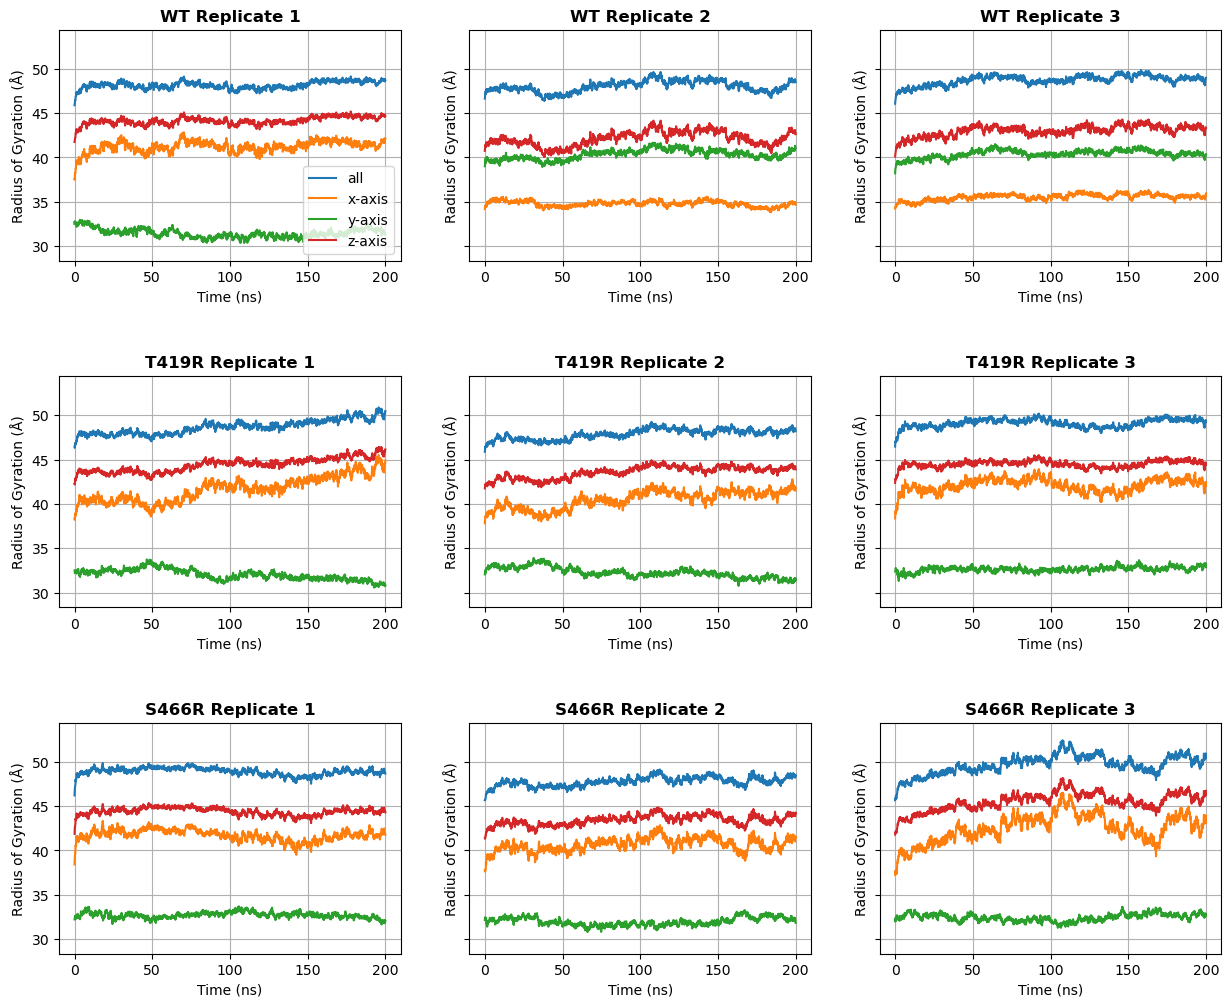

In [36]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharey=True)

labels = ['all', 'x-axis', 'y-axis', 'z-axis']

# Plot WT replicates
for i, (df, ax) in enumerate(zip(wt_radius, axes[0])):
    for col, label in zip(df, labels):
        ax.plot(df['Frame'] / 10, df[label], label=label)
    ax.set_title(f'WT Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel('Radius of Gyration (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)
    if i == 0:  
        ax.legend()

# Plot T419R replicates
for i, (df, ax) in enumerate(zip(T419R_radius, axes[1])):
    for col, label in zip(df, labels):
        ax.plot(df['Frame'] / 10, df[label], label=label)
    ax.set_title(f'T419R Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel('Radius of Gyration (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

# Plot S466R replicates
for i, (df, ax) in enumerate(zip(S466R_radius, axes[2])):
    for col, label in zip(df, labels):
        ax.plot(df['Frame'] / 10, df[label], label=label)
    ax.set_title(f'S466R Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('Time (ns)')
    ax.set_ylabel('Radius of Gyration (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)


plt.subplots_adjust(hspace=0.5)
plt.show()

In [37]:
all_radius = wt_radius + S466R_radius + S466R_radius
y_min = min(df['all'].min() for df in all_radius) - 1
y_max = max(df['all'].max() for df in all_radius) + 1

x_min = min(df['C-alphas'].min() for df in all_rmsd)
x_max = max(df['C-alphas'].max() for df in all_rmsd)

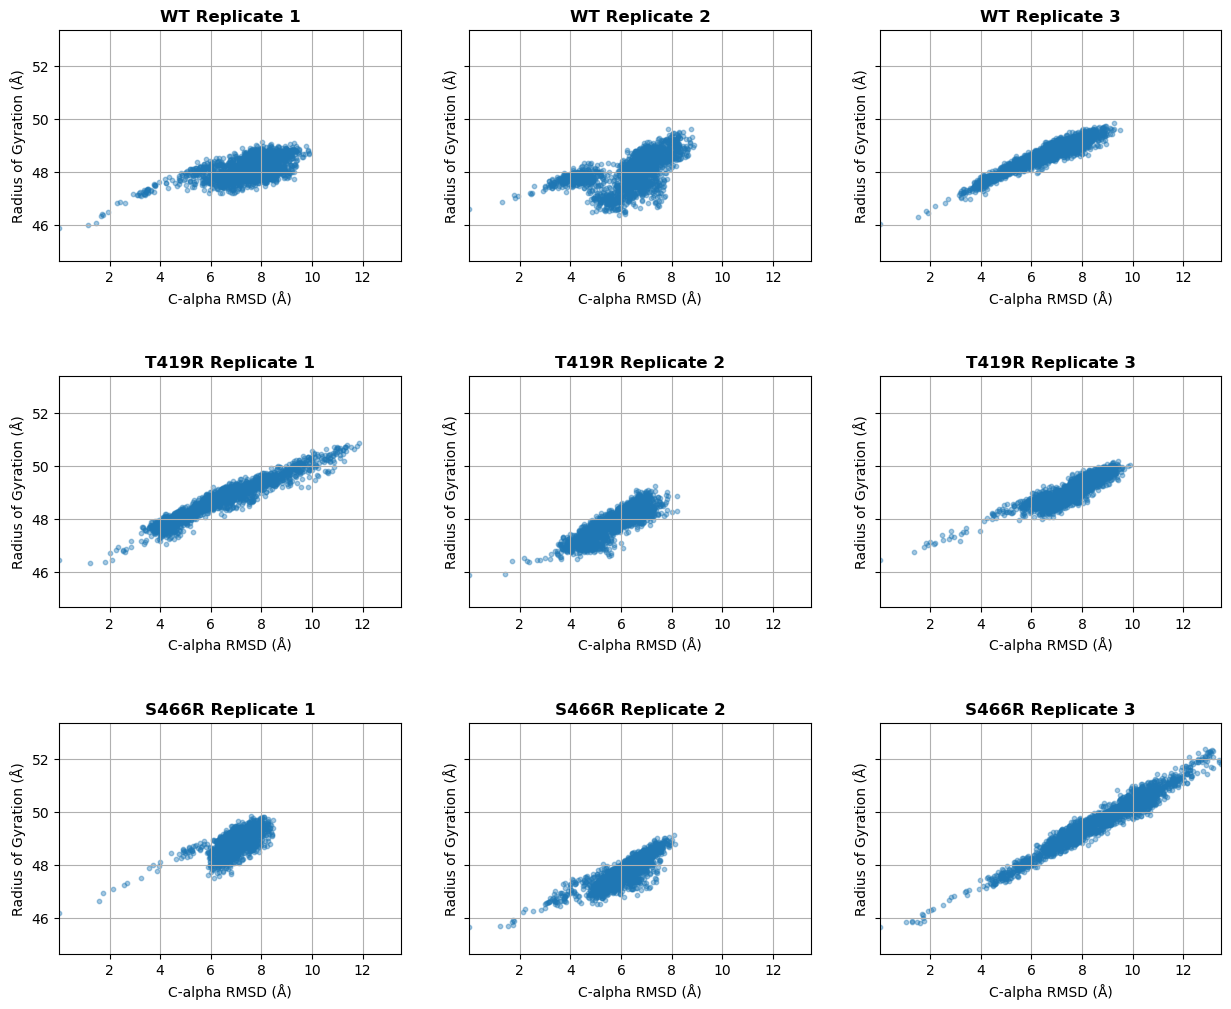

In [39]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharey=True)

labels = ['all', 'x-axis', 'y-axis', 'z-axis']

# Plot WT replicates
for i, (rmsd, radius, ax) in enumerate(zip(wt_rmsd, wt_radius, axes[0])):
    ax.scatter(rmsd['C-alphas'], radius['all'], s=10, alpha=0.4, label="RMSD vs Radius of gyration")
    ax.set_title(f'WT Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('C-alpha RMSD (Å)')
    ax.set_ylabel('Radius of Gyration (Å)')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

# Plot T419R replicates
for i, (rmsd, radius, ax) in enumerate(zip(T419R_rmsd, T419R_radius, axes[1])):
    ax.scatter(rmsd['C-alphas'], radius['all'], s=10, alpha=0.4, label="RMSD vs Radius of gyration")
    ax.set_title(f'T419R Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('C-alpha RMSD (Å)')
    ax.set_ylabel('Radius of Gyration (Å)')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

# Plot S466R replicates
for i, (rmsd, radius, ax) in enumerate(zip(S466R_rmsd, S466R_radius, axes[2])):
    ax.scatter(rmsd['C-alphas'], radius['all'], s=10, alpha=0.4, label="RMSD vs Radius of gyration")
    ax.set_title(f'S466R Replicate {i+1}', fontweight="bold")
    ax.set_xlabel('C-alpha RMSD (Å)')
    ax.set_ylabel('Radius of Gyration (Å)')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)  

plt.subplots_adjust(hspace=0.5)
plt.show()

# RMSF

## Protein

In [10]:
wt_rmsf_prot= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/001_qc/rmsf_prot.csv')
    wt_rmsf_prot.append(df)

T419R_rmsf_prot= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/001_qc/rmsf_prot.csv')
    T419R_rmsf_prot.append(df)

S466R_rmsf_prot= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/001_qc/rmsf_prot.csv')
    S466R_rmsf_prot.append(df)

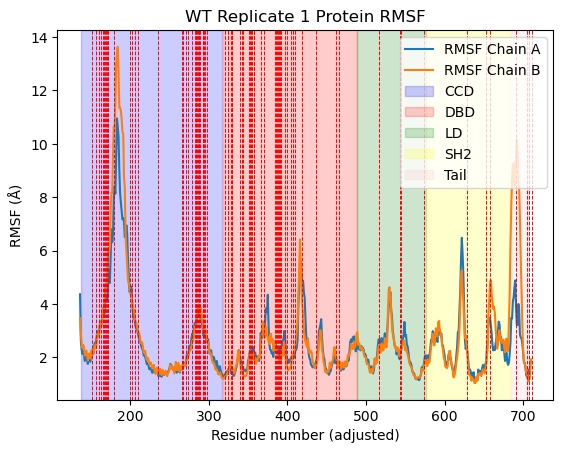

In [11]:
plt.plot(wt_rmsf_prot[0]['Residue'] + 135, wt_rmsf_prot[0]['RMSF_A'], label='RMSF Chain A')
plt.plot(wt_rmsf_prot[0]['Residue'] + 135, wt_rmsf_prot[0]['RMSF_B'], label='RMSF Chain B')
plt.axvspan(137, 317, zorder=0, alpha=0.2, color='blue', label='CCD')
plt.axvspan(318, 488, zorder=0, alpha=0.2, color='red', label='DBD')
plt.axvspan(489, 576, zorder=0, alpha=0.2, color='green', label='LD')
plt.axvspan(577, 683, zorder=0, alpha=0.2, color='yellow', label='SH2')
plt.axvspan(684, 708, zorder=0, alpha=0.2, color='pink', label='Tail')

# mutations from Guo et al. 2024
muts = [151, 156, 160, 163, 165, 167,168, 169, 170, 171, 172, 179, 199, 202, 206, 
        210, 235, 266, 267, 271, 274, 278, 282, 283, 284, 285, 286, 287, 288, 289, 
        292, 293, 294, 295, 298, 321, 324, 325, 328, 329, 330, 340, 342, 344, 351, 
        353, 354, 355, 357, 358, 366, 370, 384, 385, 387, 388, 389, 390, 392, 397, 
        400, 404, 407, 410, 419, 437, 462, 466, 517, 543, 545, 574, 629, 653, 658,
        691, 705, 708, 711]
for mut in muts:
    plt.axvline(x=mut, color='red', linestyle='--', lw=0.7)

plt.xlabel('Residue number (adjusted)')
plt.ylabel('RMSF (Å)')
plt.title('WT Replicate 1 Protein RMSF')
plt.legend()
plt.show()

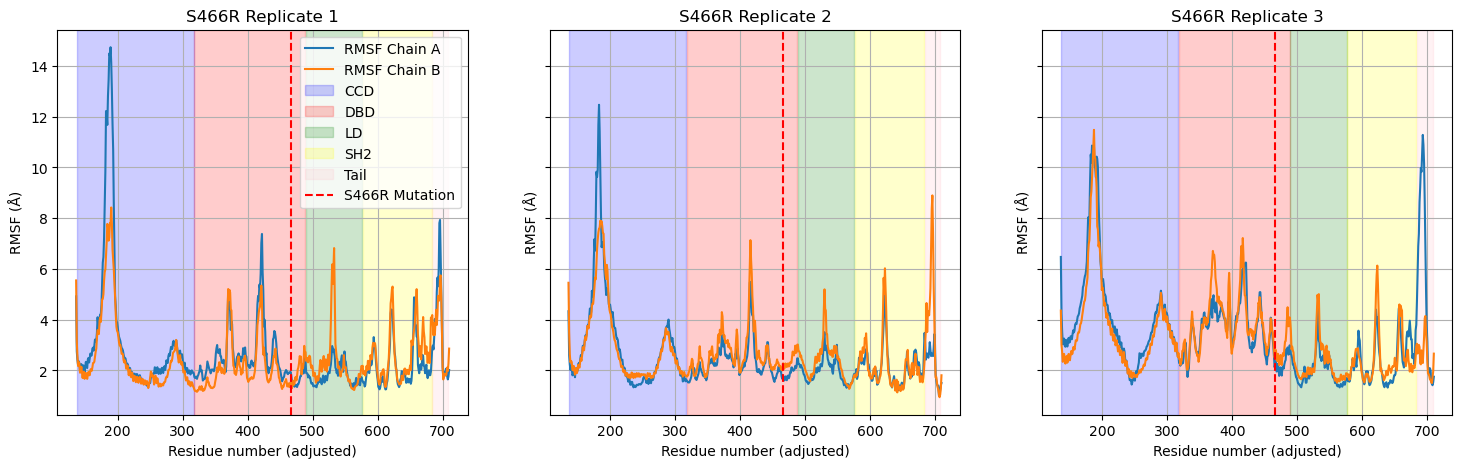

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i in range(len(S466R_rmsf_prot)):
    axes[i].plot(S466R_rmsf_prot[i]['Residue'] + 135, S466R_rmsf_prot[i]['RMSF_A'], label='RMSF Chain A')
    axes[i].plot(S466R_rmsf_prot[i]['Residue'] + 135, S466R_rmsf_prot[i]['RMSF_B'], label='RMSF Chain B')
    axes[i].axvspan(137, 317, zorder=0, alpha=0.2, color='blue', label='CCD')
    axes[i].axvspan(318, 488, zorder=0, alpha=0.2, color='red', label='DBD')
    axes[i].axvspan(489, 576, zorder=0, alpha=0.2, color='green', label='LD')
    axes[i].axvspan(577, 683, zorder=0, alpha=0.2, color='yellow', label='SH2')
    axes[i].axvspan(684, 708, zorder=0, alpha=0.2, color='pink', label='Tail')
    axes[i].set(title=f'S466R Replicate {i+1}', ylabel='RMSF (Å)', xlabel='Residue number (adjusted)')
    axes[i].axvline(x=466, color='red', linestyle='--', label='S466R Mutation')
    axes[i].grid(True)
    if i == 0:  # Show legend only in the first plot
        axes[i].legend()
plt.show()

In [13]:
wt_rmsf_prot_avg = pd.concat([df[['Residue', 'RMSF_A', 'RMSF_B']] for df in wt_rmsf_prot]).groupby('Residue').mean().reset_index()
T419R_rmsf_prot_avg = pd.concat([df[['Residue', 'RMSF_A', 'RMSF_B']] for df in T419R_rmsf_prot]).groupby('Residue').mean().reset_index()
S466R_rmsf_prot_avg = pd.concat([df[['Residue', 'RMSF_A', 'RMSF_B']] for df in S466R_rmsf_prot]).groupby('Residue').mean().reset_index()

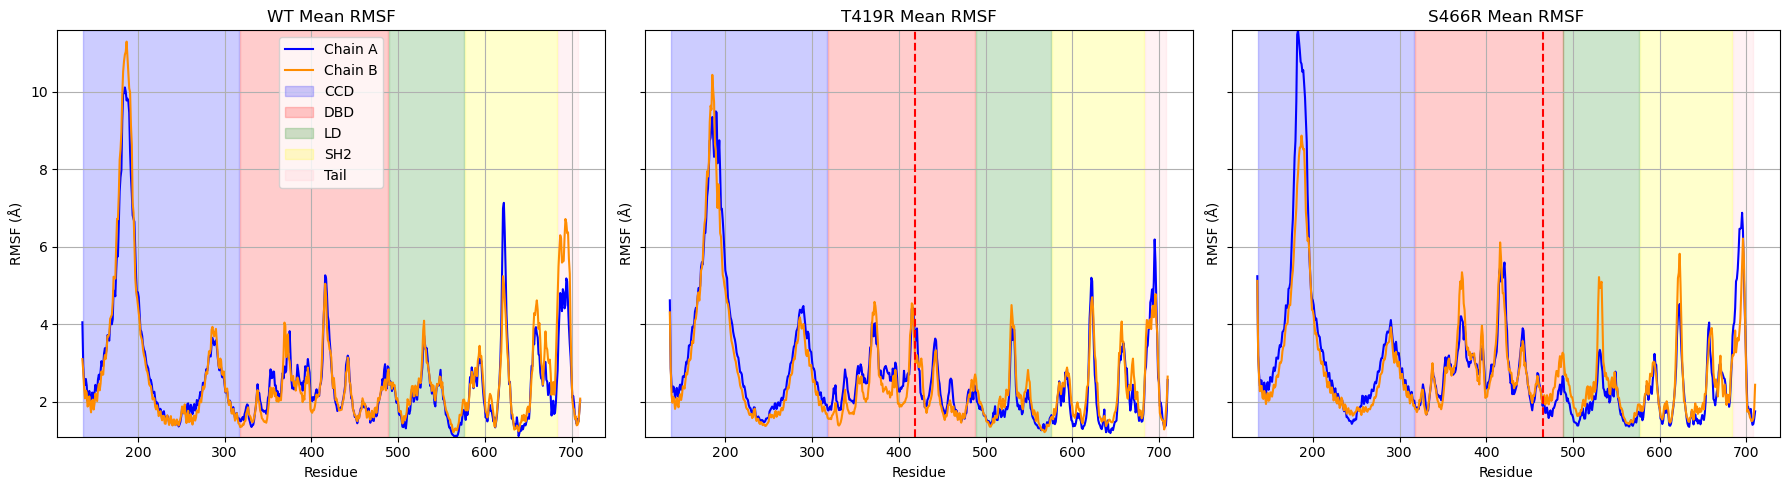

In [14]:
# Combine data for y-axis limits
data = [wt_rmsf_prot_avg, T419R_rmsf_prot_avg, S466R_rmsf_prot_avg]
labels = ['RMSF_A', 'RMSF_B']
y_min = min(df[col].min() for df in data for col in labels)
y_max = max(df[col].max() for df in data for col in labels)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Plot data
for i, (df, ax, title) in enumerate(zip(data, axes, ['WT Mean RMSF', 'T419R Mean RMSF', 'S466R Mean RMSF'])):
    ax.plot(df['Residue'] + 135, df['RMSF_A'], label='Chain A', color='blue')
    ax.plot(df['Residue'] + 135, df['RMSF_B'], label='Chain B', color='darkorange')
    ax.axvspan(137, 317, zorder=0, alpha=0.2, color='blue', label='CCD')
    ax.axvspan(318, 488, zorder=0, alpha=0.2, color='red', label='DBD')
    ax.axvspan(489, 576, zorder=0, alpha=0.2, color='green', label='LD')
    ax.axvspan(577, 683, zorder=0, alpha=0.2, color='yellow', label='SH2')
    ax.axvspan(684, 708, zorder=0, alpha=0.2, color='pink', label='Tail')
    ax.set(title=title, xlabel='Residue', ylabel='RMSF (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)
    if i == 0:  # Show legend only in the first plot
        ax.legend()
    # Add vertical to mark the mutations
    if i == 1:  # T419R 
        ax.axvline(x=419, color='red', linestyle='--', label='T419R Mutation')
    if i == 2:  # S466R
        ax.axvline(x=466, color='red', linestyle='--', label='S466R Mutation')

plt.tight_layout()
plt.show()

In [15]:
wt_stats = pd.concat([df[['Residue', 'RMSF_A', 'RMSF_B']] for df in wt_rmsf_prot]).groupby('Residue').agg(['mean', 'std']).reset_index()
T419R_stats = pd.concat([df[['Residue', 'RMSF_A', 'RMSF_B']] for df in T419R_rmsf_prot]).groupby('Residue').agg(['mean', 'std']).reset_index()
S466R_stats = pd.concat([df[['Residue', 'RMSF_A', 'RMSF_B']] for df in S466R_rmsf_prot]).groupby('Residue').agg(['mean', 'std']).reset_index()

In [16]:
wt_stats.head()

Residue    RMSF_A              RMSF_B          
               mean       std      mean       std
0       1  4.054333  0.285948  3.104922  0.346402
1       2  2.935040  0.479857  2.797238  0.091094
2       3  2.533181  0.430682  2.361712  0.227764
3       4  2.435249  0.561098  2.092355  0.245328
4       5  2.594582  0.630284  2.293354  0.184355

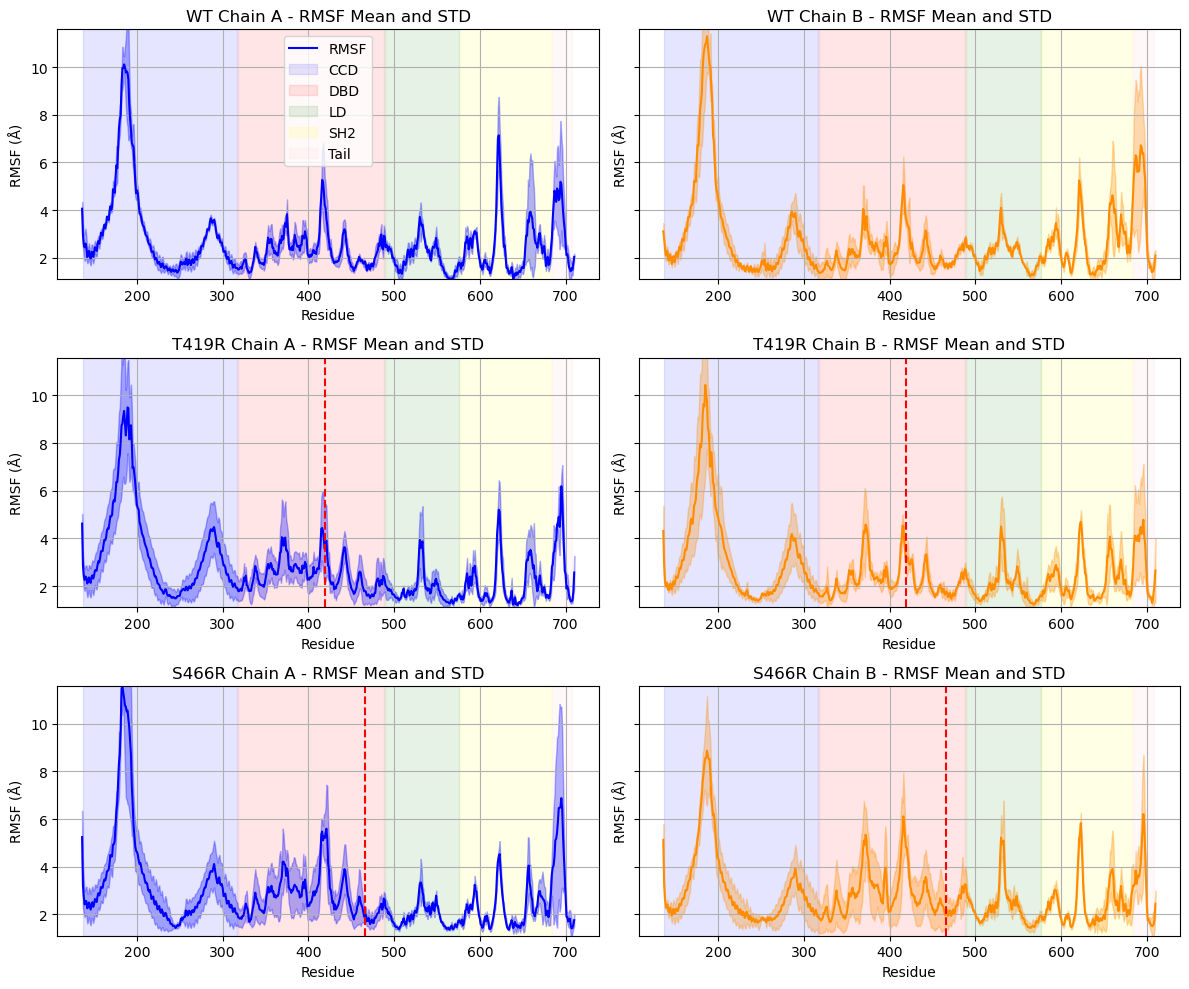

In [17]:
# Flatten multi-level column names
wt_stats.columns = ['Residue', 'RMSF_A_mean', 'RMSF_A_std', 'RMSF_B_mean', 'RMSF_B_std']
T419R_stats.columns = ['Residue', 'RMSF_A_mean', 'RMSF_A_std', 'RMSF_B_mean', 'RMSF_B_std']
S466R_stats.columns = ['Residue', 'RMSF_A_mean', 'RMSF_A_std', 'RMSF_B_mean', 'RMSF_B_std']

# Combine data for y-axis limits
data = [wt_stats, T419R_stats, S466R_stats]
labels = ['RMSF_A_mean', 'RMSF_B_mean']
y_min = min(df[col].min() for df in data for col in labels)
y_max = max(df[col].max() for df in data for col in labels)

# Create 3x2 subplot grid
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True)

# Plot data
plots = [
    (wt_stats, axes[0, 0], 'WT Chain A - RMSF Mean and STD', 'RMSF_A_mean', 'RMSF_A_std', 'blue'),
    (wt_stats, axes[0, 1], 'WT Chain B - RMSF Mean and STD', 'RMSF_B_mean', 'RMSF_B_std', 'darkorange'),
    (T419R_stats, axes[1, 0], 'T419R Chain A - RMSF Mean and STD', 'RMSF_A_mean', 'RMSF_A_std', 'blue'),
    (T419R_stats, axes[1, 1], 'T419R Chain B - RMSF Mean and STD', 'RMSF_B_mean', 'RMSF_B_std', 'darkorange'),
    (S466R_stats, axes[2, 0], 'S466R Chain A - RMSF Mean and STD', 'RMSF_A_mean', 'RMSF_A_std', 'blue'),
    (S466R_stats, axes[2, 1], 'S466R Chain B - RMSF Mean and STD', 'RMSF_B_mean', 'RMSF_B_std', 'darkorange')
]

for i, (df, ax, title, mean_col, std_col, color) in enumerate(plots):
    ax.plot(df['Residue'] + 135, df[mean_col], label=mean_col.split('_')[0], color=color)
    ax.fill_between(df['Residue'] + 135, 
                    df[mean_col] - df[std_col], 
                    df[mean_col] + df[std_col], 
                    color=color, alpha=0.3)
    ax.axvspan(137, 317, zorder=0, alpha=0.1, color='blue', label='CCD')
    ax.axvspan(318, 488, zorder=0, alpha=0.1, color='red', label='DBD')
    ax.axvspan(489, 576, zorder=0, alpha=0.1, color='green', label='LD')
    ax.axvspan(577, 683, zorder=0, alpha=0.1, color='yellow', label='SH2')
    ax.axvspan(684, 708, zorder=0, alpha=0.1, color='pink', label='Tail')
    
    # Add vertical to mark the mutations
    if i in [2, 3]:  # T419R plots (second row)
        ax.axvline(x=419, color='red', linestyle='--', label='T419R Mutation')
    if i in [4, 5]:  # S466R plots (third row)
        ax.axvline(x=466, color='red', linestyle='--', label='S466R Mutation')
    
    ax.set(title=title, xlabel='Residue', ylabel='RMSF (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)
    if i == 0:  # Show legend only in the first plot (WT RMSF_A)
        ax.legend()

plt.tight_layout()
plt.show()

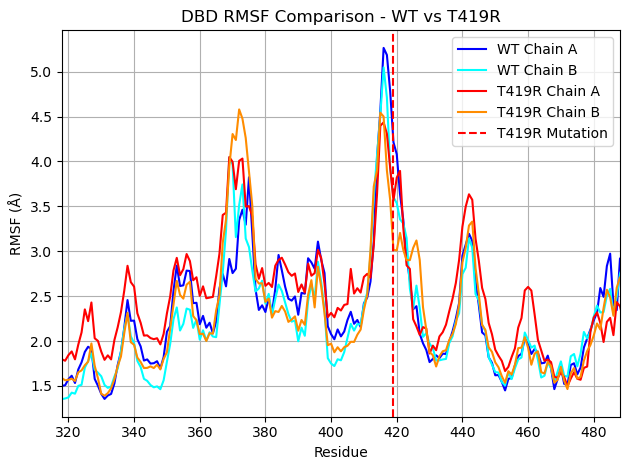

In [18]:
plt.plot(wt_stats['Residue'] + 135, wt_stats['RMSF_A_mean'], label='WT Chain A', color='blue')
plt.plot(wt_stats['Residue'] + 135, wt_stats['RMSF_B_mean'], label='WT Chain B', color='cyan')
plt.plot(T419R_stats['Residue'] + 135, T419R_stats['RMSF_A_mean'], label='T419R Chain A', color='red')
plt.plot(T419R_stats['Residue'] + 135, T419R_stats['RMSF_B_mean'], label='T419R Chain B', color='darkorange')

plt.axvline(x=419, color='red', linestyle='--', label='T419R Mutation')

# Filter data within x-axis range (318 to 488)
mask_wt = (wt_stats['Residue'] + 135 >= 318) & (wt_stats['Residue'] + 135 <= 488)
mask_T419R = (T419R_stats['Residue'] + 135 >= 318) & (T419R_stats['Residue'] + 135 <= 488)

# Collect all y-values within the x-axis range
y_values = np.concatenate([
    wt_stats[mask_wt]['RMSF_A_mean'].values,
    wt_stats[mask_wt]['RMSF_B_mean'].values,
    T419R_stats[mask_T419R]['RMSF_A_mean'].values,
    T419R_stats[mask_T419R]['RMSF_B_mean'].values
])

# Calculate y-axis limits with a small padding (e.g., 5% of the range)
y_min, y_max = np.min(y_values), np.max(y_values)
padding = (y_max - y_min) * 0.05
plt.ylim(y_min - padding, y_max + padding)
plt.xlim(318, 488)
plt.title('DBD RMSF Comparison - WT vs T419R')
plt.xlabel('Residue')
plt.ylabel('RMSF (Å)')
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

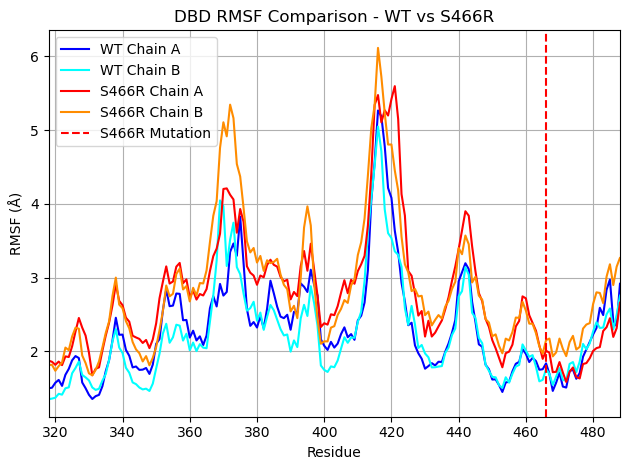

In [21]:
plt.plot(wt_stats['Residue'] + 135, wt_stats['RMSF_A_mean'], label='WT Chain A', color='blue')
plt.plot(wt_stats['Residue'] + 135, wt_stats['RMSF_B_mean'], label='WT Chain B', color='cyan')
plt.plot(S466R_stats['Residue'] + 135, S466R_stats['RMSF_A_mean'], label='S466R Chain A', color='red')
plt.plot(S466R_stats['Residue'] + 135, S466R_stats['RMSF_B_mean'], label='S466R Chain B', color='darkorange')

plt.axvline(x=466, color='red', linestyle='--', label='S466R Mutation')

# Filter data within x-axis range (318 to 488)
mask_wt = (wt_stats['Residue'] + 135 >= 318) & (wt_stats['Residue'] + 135 <= 488)
mask_S466R = (S466R_stats['Residue'] + 135 >= 318) & (S466R_stats['Residue'] + 135 <= 488)

# Collect all y-values within the x-axis range
y_values = np.concatenate([
    wt_stats[mask_wt]['RMSF_A_mean'].values,
    wt_stats[mask_wt]['RMSF_B_mean'].values,
    S466R_stats[mask_T419R]['RMSF_A_mean'].values,
    S466R_stats[mask_T419R]['RMSF_B_mean'].values
])

# Calculate y-axis limits with a small padding (e.g., 5% of the range)
y_min, y_max = np.min(y_values), np.max(y_values)
padding = (y_max - y_min) * 0.05
plt.ylim(y_min - padding, y_max + padding)
plt.xlim(318, 488)
plt.title('DBD RMSF Comparison - WT vs S466R')
plt.xlabel('Residue')
plt.ylabel('RMSF (Å)')
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

In [46]:
residue_of_interest = 419 - 135  # Corresponds to Residue 284 in the stats DataFrames

for name, df in zip(['WT', 'T419R', 'S466R'], [wt_stats, T419R_stats, S466R_stats]):
    row = df[df['Residue'] == residue_of_interest]
    if not row.empty:
        print(f"{name} - Residue 419 (index {residue_of_interest}):")
        print(f"  Chain A: RMSF Mean = {row['RMSF_A_mean'].values[0]:.3f} Å, Std = {row['RMSF_A_std'].values[0]:.3f} Å")
        print(f"  Chain B: RMSF Mean = {row['RMSF_B_mean'].values[0]:.3f} Å, Std = {row['RMSF_B_std'].values[0]:.3f} Å\n")
    else:
        print(f"{name} - Residue {residue_of_interest} not found in data.\n")


WT - Residue 419 (index 284):
  Chain A: RMSF Mean = 4.214 Å, Std = 1.128 Å
  Chain B: RMSF Mean = 3.602 Å, Std = 0.340 Å

T419R - Residue 419 (index 284):
  Chain A: RMSF Mean = 3.566 Å, Std = 1.366 Å
  Chain B: RMSF Mean = 3.017 Å, Std = 0.444 Å

S466R - Residue 419 (index 284):
  Chain A: RMSF Mean = 5.196 Å, Std = 1.014 Å
  Chain B: RMSF Mean = 4.803 Å, Std = 0.249 Å



Confidence intervals (95%)

In [47]:
# Sample size (reps) and z-score for 95% confidence
n = 3
z = 1.96

def add_ci_columns(df):
    for chain in ['A', 'B']:
        mean_col = f'RMSF_{chain}_mean'
        std_col = f'RMSF_{chain}_std'
        ci = z * df[std_col] / np.sqrt(n)
        df[f'RMSF_{chain}_CI_lower'] = df[mean_col] - ci
        df[f'RMSF_{chain}_CI_upper'] = df[mean_col] + ci
    return df


In [48]:
wt_stats = add_ci_columns(wt_stats)
T419R_stats = add_ci_columns(T419R_stats)
S466R_stats = add_ci_columns(S466R_stats)

In [49]:
wt_stats.head()

,Residue,RMSF_A_mean,RMSF_A_std,RMSF_B_mean,RMSF_B_std,RMSF_A_CI_lower,RMSF_A_CI_upper,RMSF_B_CI_lower,RMSF_B_CI_upper
0,1,4.054333,0.285948,3.104922,0.346402,3.730752,4.377914,2.712931,3.496912
1,2,2.935040,0.479857,2.797238,0.091094,2.392030,3.478050,2.694155,2.900321
2,3,2.533181,0.430682,2.361712,0.227764,2.045818,3.020543,2.103973,2.619451
3,4,2.435249,0.561098,2.092355,0.245328,1.800307,3.070191,1.814740,2.369971
4,5,2.594582,0.630284,2.293354,0.184355,1.881349,3.307815,2.084737,2.501971


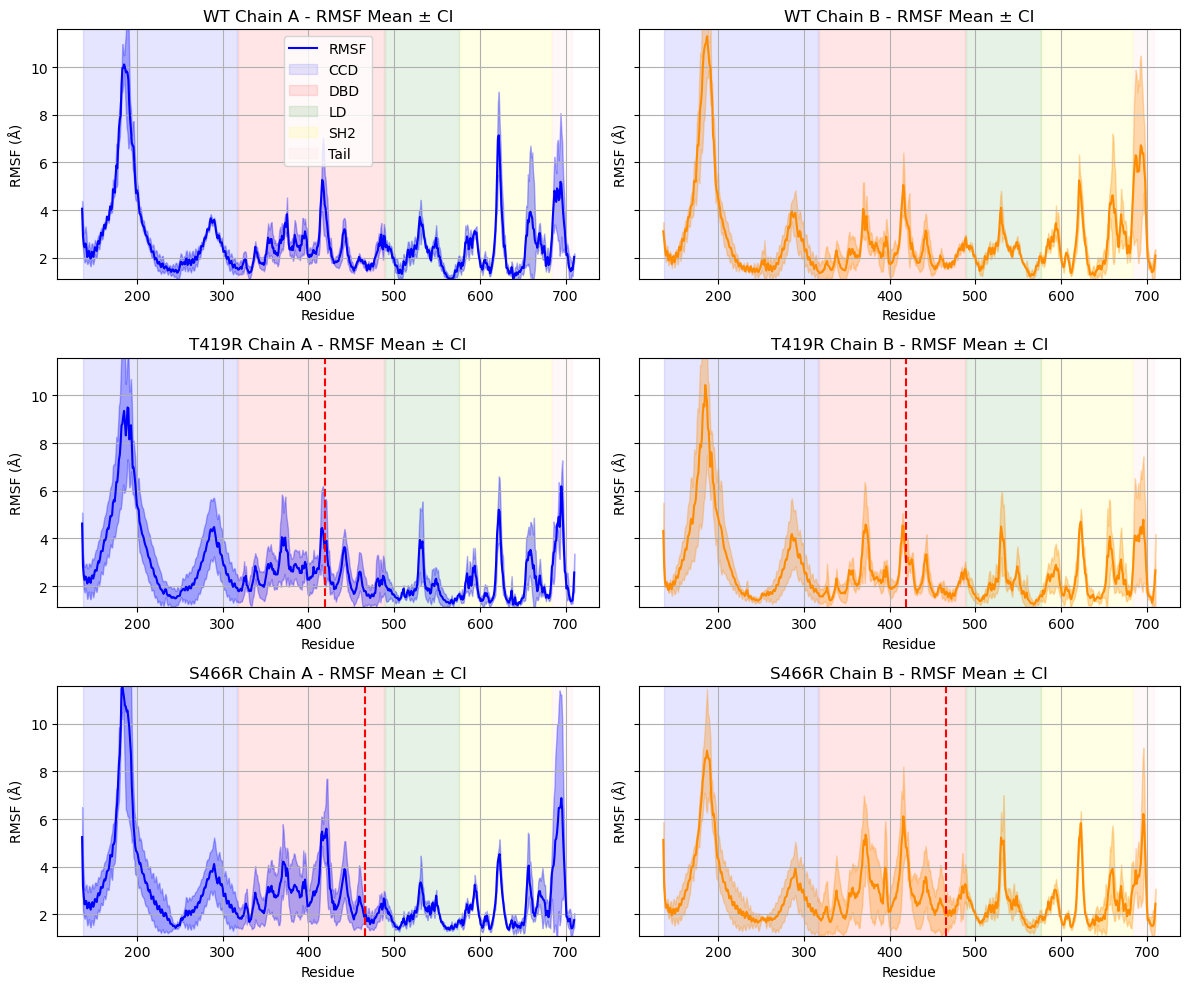

In [50]:
# Create 3x2 subplot grid
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True)

# Plot info: use CI columns
plots = [
    (wt_stats, axes[0, 0], 'WT Chain A - RMSF Mean ± CI', 'RMSF_A_mean', 'RMSF_A_CI_lower', 'RMSF_A_CI_upper', 'blue'),
    (wt_stats, axes[0, 1], 'WT Chain B - RMSF Mean ± CI', 'RMSF_B_mean', 'RMSF_B_CI_lower', 'RMSF_B_CI_upper', 'darkorange'),
    (T419R_stats, axes[1, 0], 'T419R Chain A - RMSF Mean ± CI', 'RMSF_A_mean', 'RMSF_A_CI_lower', 'RMSF_A_CI_upper', 'blue'),
    (T419R_stats, axes[1, 1], 'T419R Chain B - RMSF Mean ± CI', 'RMSF_B_mean', 'RMSF_B_CI_lower', 'RMSF_B_CI_upper', 'darkorange'),
    (S466R_stats, axes[2, 0], 'S466R Chain A - RMSF Mean ± CI', 'RMSF_A_mean', 'RMSF_A_CI_lower', 'RMSF_A_CI_upper', 'blue'),
    (S466R_stats, axes[2, 1], 'S466R Chain B - RMSF Mean ± CI', 'RMSF_B_mean', 'RMSF_B_CI_lower', 'RMSF_B_CI_upper', 'darkorange')
]

for i, (df, ax, title, mean_col, ci_lower_col, ci_upper_col, color) in enumerate(plots):
    x = df['Residue'] + 135
    ax.plot(x, df[mean_col], label=mean_col.split('_')[0], color=color)
    ax.fill_between(x, df[ci_lower_col], df[ci_upper_col], color=color, alpha=0.3)

    # Domain highlights
    ax.axvspan(137, 317, zorder=0, alpha=0.1, color='blue', label='CCD')
    ax.axvspan(318, 488, zorder=0, alpha=0.1, color='red', label='DBD')
    ax.axvspan(489, 576, zorder=0, alpha=0.1, color='green', label='LD')
    ax.axvspan(577, 683, zorder=0, alpha=0.1, color='yellow', label='SH2')
    ax.axvspan(684, 708, zorder=0, alpha=0.1, color='pink', label='Tail')

    # Mutation markers
    if i in [2, 3]:
        ax.axvline(x=419, color='red', linestyle='--', label='T419R Mutation')
    if i in [4, 5]:
        ax.axvline(x=466, color='red', linestyle='--', label='S466R Mutation')

    ax.set(title=title, xlabel='Residue', ylabel='RMSF (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)
    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()


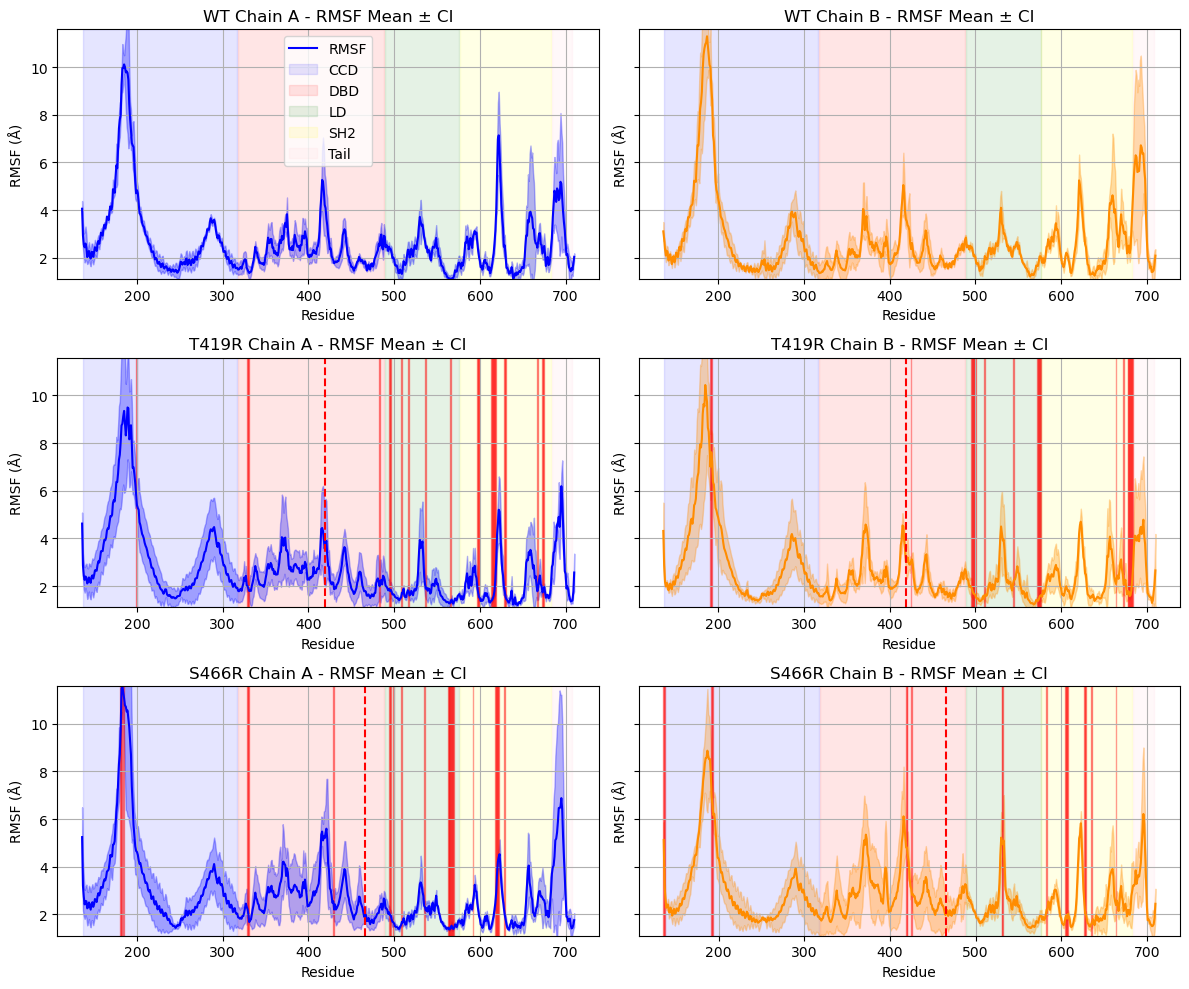

In [51]:
def highlight_nonoverlap(ax, x_vals, wt_low, wt_up, mut_low, mut_up, color='red', alpha=0.4):
    nonoverlap = (mut_low > wt_up) | (mut_up < wt_low)
    for x, flag in zip(x_vals, nonoverlap):
        if flag:
            ax.axvspan(x - 0.5, x + 0.5, color=color, alpha=alpha, zorder=1)

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True)

plots = [
    (wt_stats, axes[0, 0], 'WT Chain A - RMSF Mean ± CI', 'RMSF_A_mean', 'RMSF_A_CI_lower', 'RMSF_A_CI_upper', 'blue', None),
    (wt_stats, axes[0, 1], 'WT Chain B - RMSF Mean ± CI', 'RMSF_B_mean', 'RMSF_B_CI_lower', 'RMSF_B_CI_upper', 'darkorange', None),
    (T419R_stats, axes[1, 0], 'T419R Chain A - RMSF Mean ± CI', 'RMSF_A_mean', 'RMSF_A_CI_lower', 'RMSF_A_CI_upper', 'blue', wt_stats),
    (T419R_stats, axes[1, 1], 'T419R Chain B - RMSF Mean ± CI', 'RMSF_B_mean', 'RMSF_B_CI_lower', 'RMSF_B_CI_upper', 'darkorange', wt_stats),
    (S466R_stats, axes[2, 0], 'S466R Chain A - RMSF Mean ± CI', 'RMSF_A_mean', 'RMSF_A_CI_lower', 'RMSF_A_CI_upper', 'blue', wt_stats),
    (S466R_stats, axes[2, 1], 'S466R Chain B - RMSF Mean ± CI', 'RMSF_B_mean', 'RMSF_B_CI_lower', 'RMSF_B_CI_upper', 'darkorange', wt_stats)
]


for i, (df, ax, title, mean_col, ci_lower_col, ci_upper_col, color, wt_df) in enumerate(plots):
    x = df['Residue'] + 135
    ax.plot(x, df[mean_col], label=mean_col.split('_')[0], color=color)
    ax.fill_between(x, df[ci_lower_col], df[ci_upper_col], color=color, alpha=0.3)

    # CI non-overlap highlight
    if wt_df is not None:
        wt_low = wt_df[ci_lower_col]
        wt_up = wt_df[ci_upper_col]
        mut_low = df[ci_lower_col]
        mut_up = df[ci_upper_col]
        highlight_nonoverlap(ax, x, wt_low, wt_up, mut_low, mut_up, color='red', alpha=0.4)

    # Domain highlights
    ax.axvspan(137, 317, zorder=0, alpha=0.1, color='blue', label='CCD')
    ax.axvspan(318, 488, zorder=0, alpha=0.1, color='red', label='DBD')
    ax.axvspan(489, 576, zorder=0, alpha=0.1, color='green', label='LD')
    ax.axvspan(577, 683, zorder=0, alpha=0.1, color='yellow', label='SH2')
    ax.axvspan(684, 708, zorder=0, alpha=0.1, color='pink', label='Tail')

    if i in [2, 3]: ax.axvline(x=419, color='red', linestyle='--', label='T419R Mutation')
    if i in [4, 5]: ax.axvline(x=466, color='red', linestyle='--', label='S466R Mutation')

    ax.set(title=title, xlabel='Residue', ylabel='RMSF (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)
    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()


CI at the mutated residue overlaps with WT's for both mutants.

## DNA

In [52]:
wt_rmsf_dna= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/001_qc/rmsf_dna.csv')
    wt_rmsf_dna.append(df)

T419R_rmsf_dna= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/001_qc/rmsf_dna.csv')
    T419R_rmsf_dna.append(df)

S466R_rmsf_dna= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/001_qc/rmsf_dna.csv')
    S466R_rmsf_dna.append(df)

In [53]:
wt_rmsf_dna_stats = pd.concat([df[['Residue', 'RMSF_C', 'RMSF_D']] for df in wt_rmsf_dna]).groupby('Residue').agg(['mean', 'std']).reset_index()
T419R_rmsf_dna_stats = pd.concat([df[['Residue', 'RMSF_C', 'RMSF_D']] for df in T419R_rmsf_dna]).groupby('Residue').agg(['mean', 'std']).reset_index()
S466R_rmsf_dna_stats = pd.concat([df[['Residue', 'RMSF_C', 'RMSF_D']] for df in S466R_rmsf_dna]).groupby('Residue').agg(['mean', 'std']).reset_index()

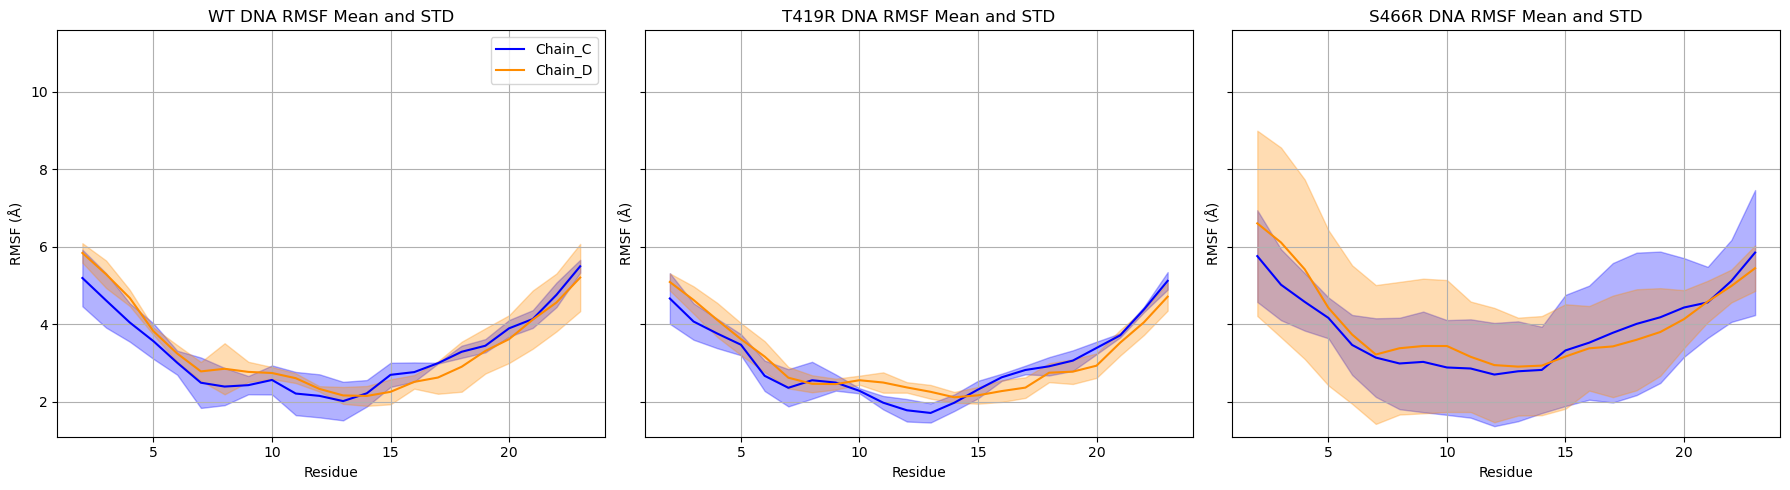

In [54]:
# Combine data for y-axis limits
data = [wt_rmsf_dna_stats, T419R_rmsf_dna_stats, S466R_rmsf_dna_stats]
labels = ['Chain_C', 'Chain_D']


# Create 1x2 subplot grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Define data for each subplot (fix data input here)
plots = [
    (wt_rmsf_dna_stats, axes[0], 'WT DNA RMSF Mean and STD', 'RMSF_C', 'RMSF_D'),
    (T419R_rmsf_dna_stats, axes[1], 'T419R DNA RMSF Mean and STD', 'RMSF_C', 'RMSF_D'),
    (S466R_rmsf_dna_stats, axes[2], 'S466R DNA RMSF Mean and STD', 'RMSF_C', 'RMSF_D')
]

for i, (df, ax, title, col_C, col_D) in enumerate(plots):
    ax.plot(df['Residue'], df[(col_C, 'mean')], label='Chain_C', color='blue')
    ax.fill_between(df['Residue'],
                    df[(col_C, 'mean')] - df[(col_C, 'std')],
                    df[(col_C, 'mean')] + df[(col_C, 'std')],
                    color='blue', alpha=0.3)

    ax.plot(df['Residue'], df[(col_D, 'mean')], label='Chain_D', color='darkorange')
    ax.fill_between(df['Residue'],
                    df[(col_D, 'mean')] - df[(col_D, 'std')],
                    df[(col_D, 'mean')] + df[(col_D, 'std')],
                    color='darkorange', alpha=0.3)

    ax.set(title=title, xlabel='Residue', ylabel='RMSF (Å)')
    ax.set_ylim(y_min, y_max)
    ax.grid(True)
    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()

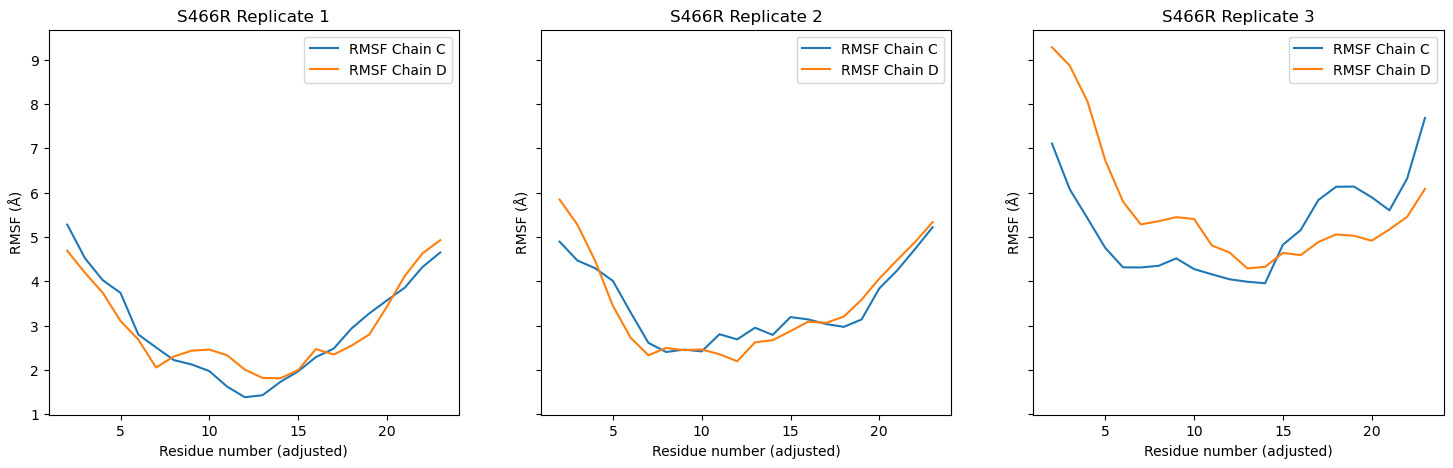

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i in range(len(S466R_rmsf_dna)):
    axes[i].plot(S466R_rmsf_dna[i]['Residue'], S466R_rmsf_dna[i]['RMSF_C'], label='RMSF Chain C')
    axes[i].plot(S466R_rmsf_dna[i]['Residue'], S466R_rmsf_dna[i]['RMSF_D'], label='RMSF Chain D')
    axes[i].set(title=f'S466R Replicate {i+1}', ylabel='RMSF (Å)', xlabel='Residue number (adjusted)')
    axes[i].legend()
plt.show()

In [56]:
wt_rmsf_dna_stats

Residue    RMSF_C              RMSF_D          
                mean       std      mean       std
0        2  5.195963  0.728990  5.841776  0.250812
1        3  4.617682  0.700495  5.292357  0.354186
2        4  4.048743  0.494845  4.680600  0.208640
3        5  3.566733  0.457678  3.823078  0.094360
4        6  3.011852  0.309691  3.249187  0.218122
5        7  2.496098  0.649762  2.788187  0.242626
6        8  2.397418  0.480194  2.855579  0.658899
7        9  2.433463  0.235314  2.775857  0.259950
8       10  2.567392  0.374398  2.746605  0.154590
9       11  2.217122  0.557067  2.613170  0.124990
10      12  2.157733  0.555148  2.337053  0.069663
11      13  2.022708  0.496670  2.168581  0.218151
12      14  2.223834  0.341047  2.155800  0.255830
13      15  2.699825  0.310756  2.261677  0.321490
14      16  2.770139  0.248775  2.518447  0.175688
15      17  2.999840  0.010497  2.630104  0.418719
16      18  3.294194  0.157115  2.908406  0.644498
17      19  3.449636  0.170634  3.315481  0.582642
18      20  3.898843  0.213364  3.619431  0.615406
19      21  4.137982  0.228789  4.123053  0.751056
20      22  4.761975  0.315857  4.565323  0.746601
21      23  5.497839  0.166224  5.207443  0.867636

## Add RMSF to PDB for visualization

Insert the average RMSF across all replicates into the PDB file.

In [98]:
def rmsf_mean_to_pdb(mut, prot_stats_df, dna_stats_df):
    """Convert RMSF mean values to a PDB file format."""

    # Rename columns
    prot_stats_df.columns = ['Residue', 'RMSF_A_mean', 'RMSF_A_std', 'RMSF_B_mean', 'RMSF_B_std', 'RMSF_A_CI_upper', 'RMSF_A_CI_lower', 'RMSF_B_CI_upper', 'RMSF_B_CI_lower']
    dna_stats_df.columns = ['Residue', 'RMSF_C_mean', 'RMSF_C_std', 'RMSF_D_mean', 'RMSF_D_std']

    # Create dictionaries for mean RMSF values
    rmsf_a_dict = dict(zip(prot_stats_df["Residue"], prot_stats_df["RMSF_A_mean"]))
    rmsf_b_dict = dict(zip(prot_stats_df["Residue"], prot_stats_df["RMSF_B_mean"]))
    rmsf_c_dict = dict(zip(dna_stats_df["Residue"], dna_stats_df["RMSF_C_mean"]))
    rmsf_d_dict = dict(zip(dna_stats_df["Residue"], dna_stats_df["RMSF_D_mean"]))

    # Calculate min and max RMSF values across all chains
    all_rmsf_values = (
        prot_stats_df['RMSF_A_mean'].tolist() +
        prot_stats_df['RMSF_B_mean'].tolist() +
        dna_stats_df['RMSF_C_mean'].tolist() +
        dna_stats_df['RMSF_D_mean'].tolist()
    )
    min_rmsf = min(all_rmsf_values)
    max_rmsf = max(all_rmsf_values)

    # Input and output PDB files
    pdb_file = f"../../data/1bf5/{mut}/rep1/gromacs/md_prot.pdb"
    output_pdb = f"../../data/1bf5/{mut}/rmsf_mean.pdb"

    # Modify PDB file to replace B-factors with mean RMSF values
    with open(pdb_file, "r") as infile, open(output_pdb, "w") as outfile:
        for line in infile:
            if line.startswith(("ATOM", "HETATM")):
                res_num = int(line[22:26].strip())
                chain_id = line[21].strip()
                # Assign RMSF based on chain
                if chain_id == "A":
                    b_factor = rmsf_a_dict.get(res_num, 0.0)
                elif chain_id == "B":
                    b_factor = rmsf_b_dict.get(res_num, 0.0)
                elif chain_id == "C":
                    b_factor = rmsf_c_dict.get(res_num, 0.0)
                elif chain_id == "D":
                    b_factor = rmsf_d_dict.get(res_num, 0.0)
                else:
                    b_factor = 0.0  # Default for other chains
                b_factor_str = f"{b_factor:6.2f}"
                new_line = line[:60] + b_factor_str + line[66:]
                outfile.write(new_line)
            else:
                # Write non-ATOM/HETATM lines unchanged
                outfile.write(line)

    print(f"Modified PDB file saved as {output_pdb}")
    print(f"Minimum RMSF value: {min_rmsf:.2f} Å")
    print(f"Maximum RMSF value: {max_rmsf:.2f} Å")

In [99]:
rmsf_mean_to_pdb('wt', wt_stats, wt_rmsf_dna_stats)
rmsf_mean_to_pdb('T419R', T419R_stats, T419R_rmsf_dna_stats)
rmsf_mean_to_pdb('S466R', S466R_stats, S466R_rmsf_dna_stats)

Modified PDB file saved as ../../data/1bf5/wt/rmsf_mean.pdb
Minimum RMSF value: 1.10 Å
Maximum RMSF value: 11.29 Å
Modified PDB file saved as ../../data/1bf5/T419R/rmsf_mean.pdb
Minimum RMSF value: 1.20 Å
Maximum RMSF value: 10.43 Å
Modified PDB file saved as ../../data/1bf5/S466R/rmsf_mean.pdb
Minimum RMSF value: 1.36 Å
Maximum RMSF value: 11.58 Å


Mean of WT - mean of mutant, focused on the DBD.

In [108]:
def rmsf_mean_diff_to_pdb(mut, wt_prot_stats, mut_prot_stats):
    """Convert RMSF mean differences to a PDB file format."""

    residue_start = 317-135  # Start DBD
    residue_end = 488-135    # End DBD


    wt_prot_stats.columns = ['Residue', 'RMSF_A_mean', 'RMSF_A_std', 'RMSF_B_mean', 'RMSF_B_std', 
                            'RMSF_A_CI_upper', 'RMSF_A_CI_lower', 'RMSF_B_CI_upper', 'RMSF_B_CI_lower']
    mut_prot_stats.columns = ['Residue', 'RMSF_A_mean', 'RMSF_A_std', 'RMSF_B_mean', 'RMSF_B_std', 
                            'RMSF_A_CI_upper', 'RMSF_A_CI_lower', 'RMSF_B_CI_upper', 'RMSF_B_CI_lower']

    # Filter for the specified residue range
    wt_prot_stats  = wt_prot_stats[(wt_prot_stats['Residue'] >= residue_start) & (wt_prot_stats['Residue'] <= residue_end)]
    mut_prot_stats = mut_prot_stats[(mut_prot_stats['Residue'] >= residue_start) & (mut_prot_stats['Residue'] <= residue_end)]

    # Merge DataFrames on Residue
    merged_df = pd.merge(
        wt_prot_stats[['Residue', 'RMSF_A_mean', 'RMSF_B_mean']],
        mut_prot_stats[['Residue', 'RMSF_A_mean', 'RMSF_B_mean']],
        on='Residue',
        suffixes=('_wt', f'_{mut}')
    )

    # Calculate differences (mut - wt) for each chain
    merged_df['RMSF_A_diff'] = merged_df['RMSF_A_mean_wt'] - merged_df[f'RMSF_A_mean_{mut}']
    merged_df['RMSF_B_diff'] = merged_df['RMSF_B_mean_wt'] - merged_df[f'RMSF_B_mean_{mut}']

    # Determine min/max for colorbar (use larger range from chain A or B)
    min_diff = min(merged_df['RMSF_A_diff'].min(), merged_df['RMSF_B_diff'].min())
    max_diff = max(merged_df['RMSF_A_diff'].max(), merged_df['RMSF_B_diff'].max())
    max_abs_diff = max(abs(min_diff), abs(max_diff))
    min_diff = -max_abs_diff  # Symmetric range around 0
    max_diff = max_abs_diff

    # Create dictionaries for differences
    rmsf_a_diff_dict = dict(zip(merged_df['Residue'], merged_df['RMSF_A_diff']))
    rmsf_b_diff_dict = dict(zip(merged_df['Residue'], merged_df['RMSF_B_diff']))

    # Input and output PDB files
    pdb_file = "../../data/1bf5/wt/rep1/gromacs/md_prot.pdb"
    output_pdb = f"../../data/1bf5/wt/rmsf_wt-{mut}_dbd.pdb"

    # Modify PDB file to assign RMSF differences to B-factor column for specified range
    with open(pdb_file, "r") as infile, open(output_pdb, "w") as outfile:
        for line in infile:
            if line.startswith(("ATOM", "HETATM")):
                res_num = int(line[22:26].strip())
                chain_id = line[21].strip()
                if (res_num >= residue_start and res_num <= residue_end):
                    if chain_id == 'A':
                        b_factor = rmsf_a_diff_dict.get(res_num, 0.0)
                    elif chain_id == 'B':
                        b_factor = rmsf_b_diff_dict.get(res_num, 0.0)
                    else:
                        b_factor = 0.0  # Default for other chains
                    b_factor_str = f"{b_factor:6.2f}"
                    new_line = line[:60] + b_factor_str + line[66:]
                else:
                    new_line = line  # Keep original B-factor for residues outside range
                outfile.write(new_line)
            else:
                outfile.write(line)

    print(f"PDB file with RMSF differences saved as {output_pdb}")
    print(f"RMSF difference range (residues {residue_start}-{residue_end}): {min_diff:.2f} to {max_diff:.2f}")

In [109]:
rmsf_mean_diff_to_pdb('T419R', wt_stats, T419R_stats)
rmsf_mean_diff_to_pdb('S466R', wt_stats, S466R_stats)

PDB file with RMSF differences saved as ../../data/1bf5/wt/rmsf_wt-T419R_dbd.pdb
RMSF difference range (residues 182-353): -1.24 to 1.24
PDB file with RMSF differences saved as ../../data/1bf5/wt/rmsf_wt-S466R_dbd.pdb
RMSF difference range (residues 182-353): -1.96 to 1.96
